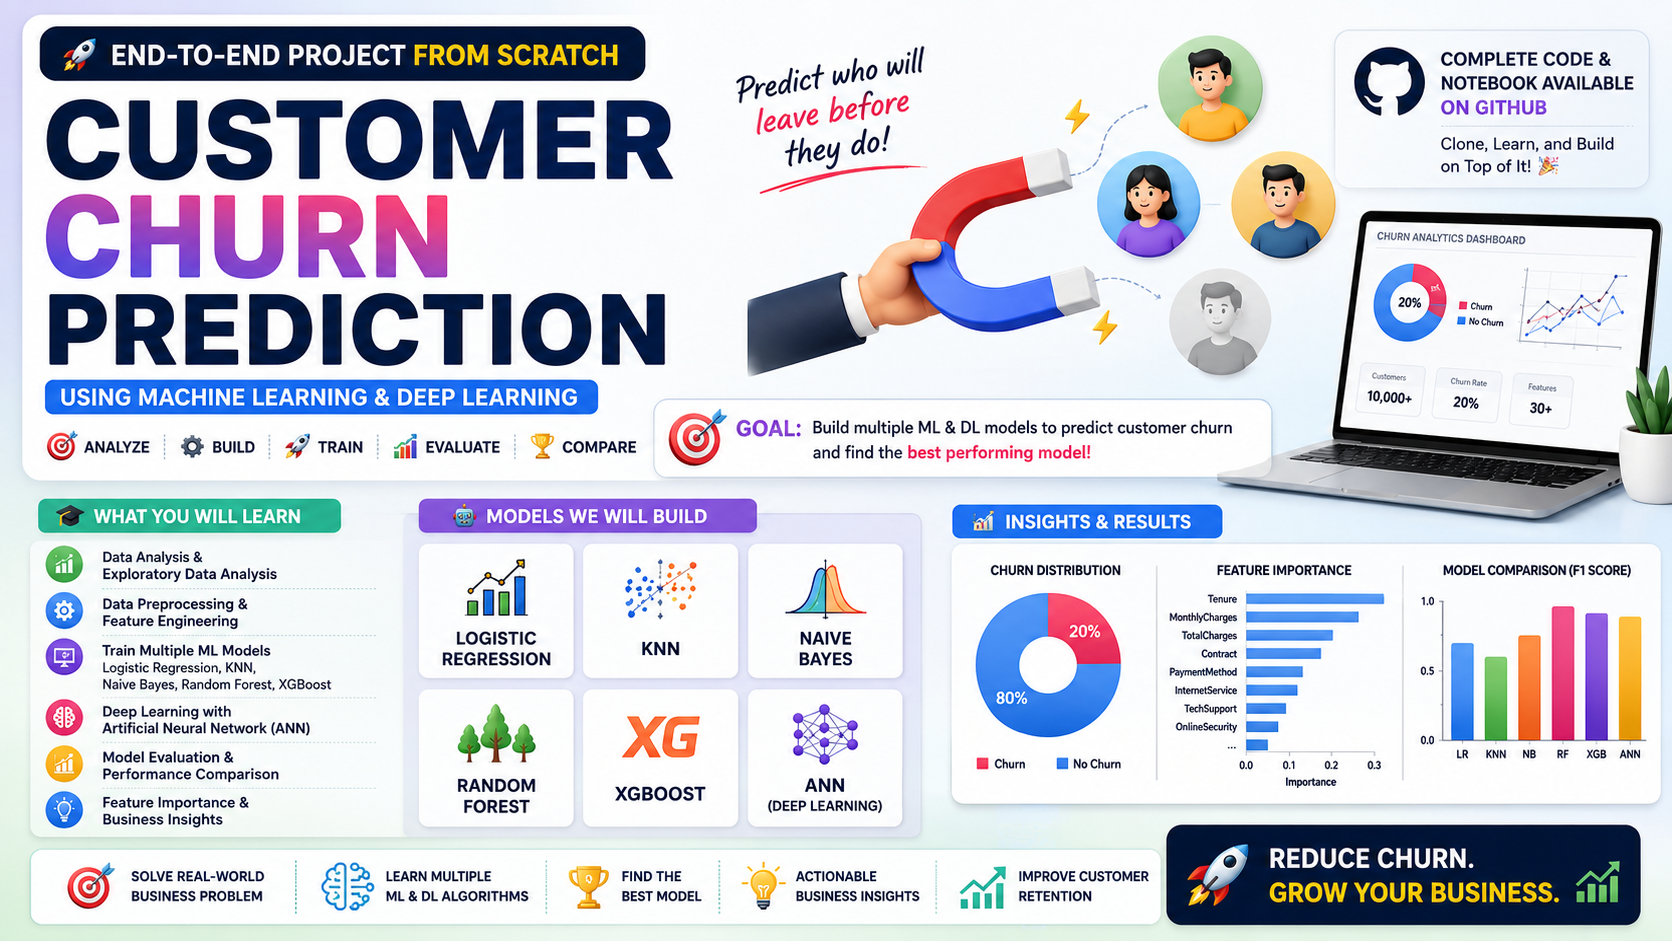

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("C:/Users/hp/Downloads/Churn_Modelling.csv")

In [3]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [4]:
df.drop(["CustomerId","Surname","RowNumber"], axis=1, inplace=True)

In [5]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [6]:
df.shape

(10000, 11)

In [7]:
df.dtypes

CreditScore          int64
Geography              str
Gender                 str
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object

**EDA - Exploratory data Analysis**

Statistical Summary

In [8]:
# statistical summary

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CreditScore      10000 non-null  int64  
 1   Geography        10000 non-null  str    
 2   Gender           10000 non-null  str    
 3   Age              10000 non-null  int64  
 4   Tenure           10000 non-null  int64  
 5   Balance          10000 non-null  float64
 6   NumOfProducts    10000 non-null  int64  
 7   HasCrCard        10000 non-null  int64  
 8   IsActiveMember   10000 non-null  int64  
 9   EstimatedSalary  10000 non-null  float64
 10  Exited           10000 non-null  int64  
dtypes: float64(2), int64(7), str(2)
memory usage: 966.1 KB


In [10]:
df.describe()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


Checking for missing values

In [11]:
df.isnull().sum()

CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

Checking the distribution of the target variable

In [12]:
df["Exited"].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

Univariate Analysis

1. Age distribution

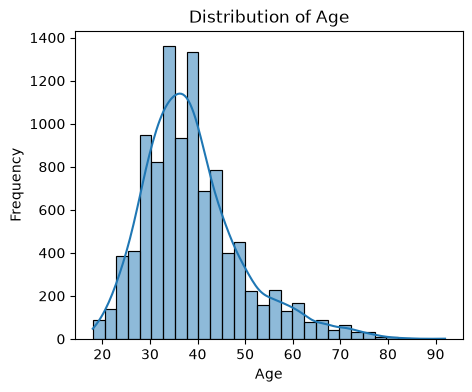

In [13]:
plt.figure(figsize=(5,4))

sns.histplot(df["Age"], bins=30, kde=True)

plt.title("Distribution of Age")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

2. Balance distribution

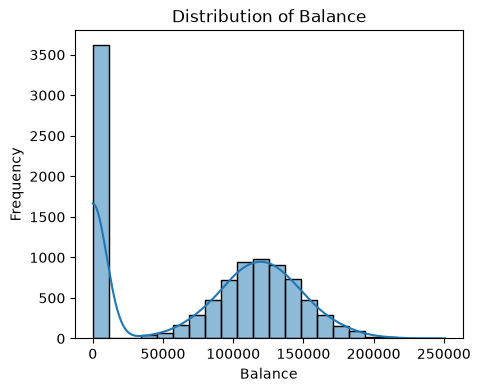

In [14]:
plt.figure(figsize=(5,4))

sns.histplot(df["Balance"], kde=True)

plt.title("Distribution of Balance")
plt.xlabel("Balance")
plt.ylabel("Frequency")

plt.show()

3. Credit Score Distribution

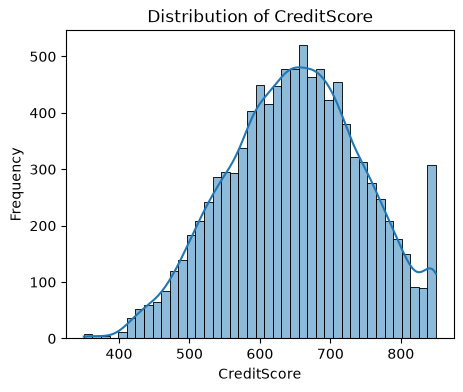

In [15]:
plt.figure(figsize=(5,4))

sns.histplot(df["CreditScore"], kde=True)

plt.title("Distribution of CreditScore")
plt.xlabel("CreditScore")
plt.ylabel("Frequency")

plt.show()

ANalysis of categorical features

1. Geography distribution

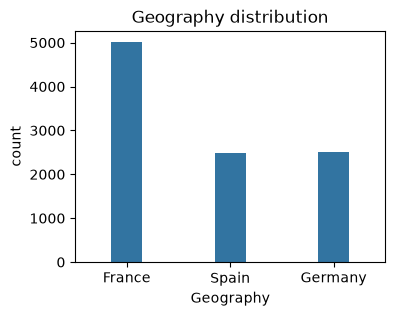

In [16]:
plt.figure(figsize=(4,3))
sns.countplot(x='Geography', data=df, width=0.3)

plt.title("Geography distribution")
plt.xlabel("Geography")
plt.ylabel("count")

plt.show()


2. Gender Distribution

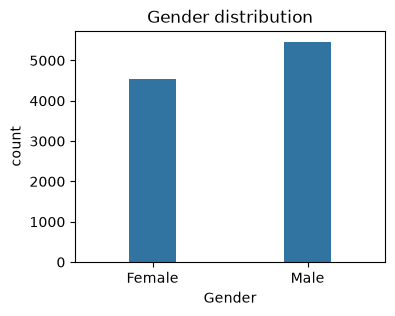

In [17]:
plt.figure(figsize=(4,3))
sns.countplot(x='Gender', data=df, width=0.3)

plt.title("Gender distribution")
plt.xlabel("Gender")
plt.ylabel("count")

plt.show()


Bivariate Analysis

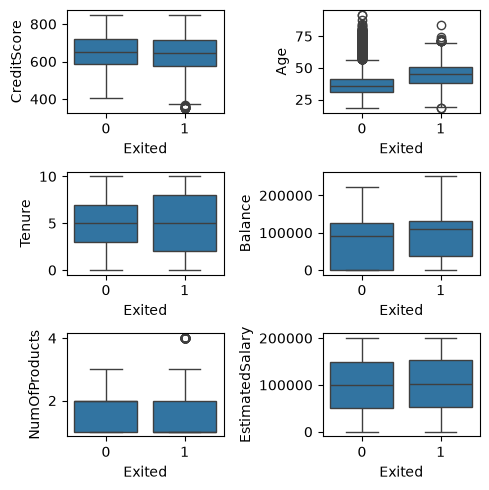

In [18]:
fig, axarr =plt.subplots(3,2, figsize=(5,5))

sns.boxplot(x='Exited', y= 'CreditScore', data=df , ax=axarr[0][0])
sns.boxplot(x='Exited', y= 'Age', data=df , ax=axarr[0][1])

sns.boxplot(x='Exited', y= 'Tenure', data=df , ax=axarr[1][0])
sns.boxplot(x='Exited', y= 'Balance', data=df , ax=axarr[1][1])

sns.boxplot(x='Exited', y= 'NumOfProducts', data=df , ax=axarr[2][0])
sns.boxplot(x='Exited', y= 'EstimatedSalary', data=df , ax=axarr[2][1])

plt.tight_layout()
plt.show()


Correlation Analysis

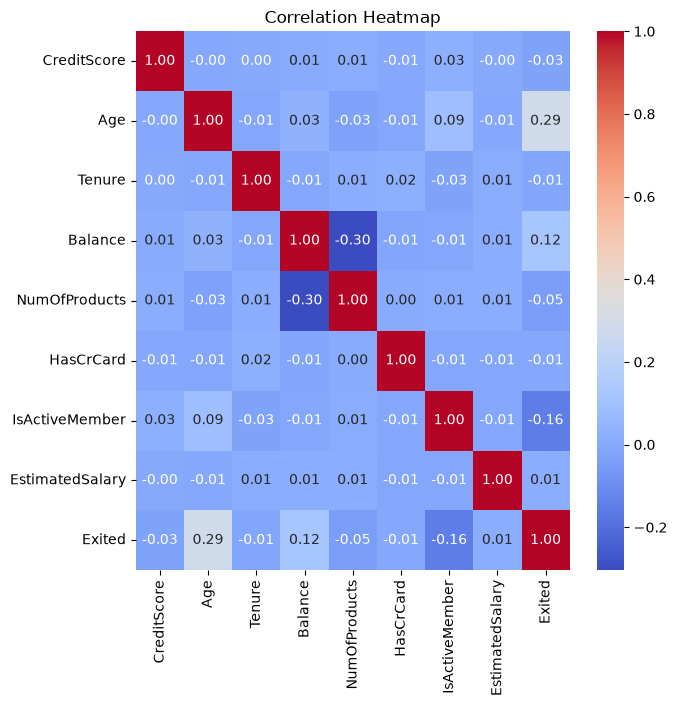

In [19]:
plt.figure(figsize=(7,7))

sns.heatmap(df.corr(numeric_only=True),
            annot=True,
            cmap='coolwarm',
            fmt='.2f')

plt.title('Correlation Heatmap')

plt.show()

Feature Engineering

1. Balance to salary ratio

In [20]:
df["balance_to_salary"]=df["Balance"]/df["EstimatedSalary"]

2. Tenure by age

In [21]:
df["tenure_by_age"]=df["Tenure"]/df["Age"]

In [22]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,balance_to_salary,tenure_by_age
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,0.000000,0.047619
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,0.744677,0.024390
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1.401375,0.190476
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0.000000,0.025641
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,1.587055,0.046512


In [23]:
df.shape

(10000, 13)

Feature Encoding

1. Label encoding - Gender

In [24]:
from sklearn.preprocessing import LabelEncoder

In [25]:
le=LabelEncoder()

In [26]:
df["Gender"]=le.fit_transform(df["Gender"])

In [27]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,balance_to_salary,tenure_by_age
0,619,France,0,42,2,0.00,1,1,1,101348.88,1,0.000000,0.047619
1,608,Spain,0,41,1,83807.86,1,0,1,112542.58,0,0.744677,0.024390
2,502,France,0,42,8,159660.80,3,1,0,113931.57,1,1.401375,0.190476
3,699,France,0,39,1,0.00,2,0,0,93826.63,0,0.000000,0.025641
4,850,Spain,0,43,2,125510.82,1,1,1,79084.10,0,1.587055,0.046512


2. One GHot encoding - Geography

In [28]:
df=pd.get_dummies(df, columns=["Geography"], drop_first=True, dtype= int)

In [29]:
df.head()

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,balance_to_salary,tenure_by_age,Geography_Germany,Geography_Spain
0,619,0,42,2,0.00,1,1,1,101348.88,1,0.000000,0.047619,0,0
1,608,0,41,1,83807.86,1,0,1,112542.58,0,0.744677,0.024390,0,1
2,502,0,42,8,159660.80,3,1,0,113931.57,1,1.401375,0.190476,0,0
3,699,0,39,1,0.00,2,0,0,93826.63,0,0.000000,0.025641,0,0
4,850,0,43,2,125510.82,1,1,1,79084.10,0,1.587055,0.046512,0,1


**Defining Features anf the Target Variable **

In [30]:
X= df.drop("Exited", axis=1)
y=df["Exited"]

**Splitting the dataset**

In [31]:
from sklearn.model_selection import train_test_split

In [32]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

In [33]:
X_train.shape

(8000, 13)

In [34]:
y_test.shape

(2000,)

Feature Scaling

In [35]:
from sklearn.preprocessing import StandardScaler

In [36]:
sc=StandardScaler()

In [37]:
X_train=sc.fit_transform(X_train)
X_test=sc.transform(X_test)

**Model Training**

1. Logistic Regression
2. KNN Classifier
3. Naive Bayes

4. Random Forest
5. XGB Classifier
6. ANN - Artificial Neural Network

In [38]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

**Logistic Regression**

In [39]:
from sklearn.linear_model import LogisticRegression

In [40]:
lr_model=LogisticRegression()

In [41]:
lr_model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [42]:
y_pred_lr = lr_model.predict(X_test)

In [43]:
lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr)
lr_recall = recall_score(y_test, y_pred_lr)
lr_f1 = f1_score(y_test, y_pred_lr)

In [44]:
print("Accuracy: ", lr_accuracy)
print("Precision: ", lr_precision)
print("recall: ", lr_recall)
print("f1 Score: ", lr_f1)

Accuracy:  0.8125
Precision:  0.56
recall:  0.21374045801526717
f1 Score:  0.30939226519337015


In [45]:
from sklearn.metrics import confusion_matrix

Text(0.5, 1.0, 'Logistic Regression Confusion Matrix')

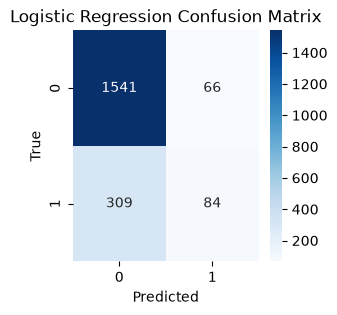

In [46]:
cm=confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(3,3))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Logistic Regression Confusion Matrix")

In [47]:
cm

array([[1541,   66],
       [ 309,   84]])

In [48]:
model_results=[]

model_results.append({"Model":"Logistic Regression",
                       "Accuracy":lr_accuracy,
                       "Precision":lr_precision,
                       "Recall":lr_recall,
                       "F1 Score":lr_f1})

2. KNN - Classifier

In [49]:
from sklearn.neighbors import KNeighborsClassifier

In [50]:
knn_model= KNeighborsClassifier()

In [51]:
knn_model.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [52]:
y_predict_knn= knn_model.predict(X_test)

In [53]:
knn_accuracy = accuracy_score(y_test, y_predict_knn)
knn_precision = precision_score(y_test, y_predict_knn)
knn_recall = recall_score(y_test, y_predict_knn)
knn_f1 = f1_score(y_test, y_predict_knn)

In [54]:
print("Accuracy: ", knn_accuracy)
print("Precision: ", knn_precision)
print("recall: ", knn_recall)
print("f1 Score: ", knn_f1)

Accuracy:  0.831
Precision:  0.6170212765957447
recall:  0.36895674300254455
f1 Score:  0.46178343949044587


Text(0.5, 1.0, 'KNN Classifier Confusion Matrix')

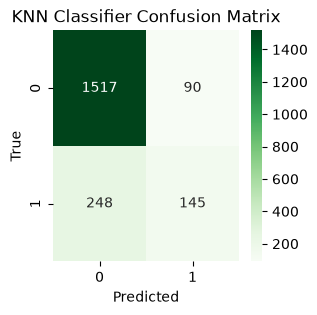

In [55]:
cm=confusion_matrix(y_test, y_predict_knn)

plt.figure(figsize=(3,3))

sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("KNN Classifier Confusion Matrix")

In [56]:
model_results.append({"Model":"KNN Classifier",
                       "Accuracy":knn_accuracy,
                       "Precision":knn_precision,
                       "Recall":knn_recall,
                       "F1 Score":knn_f1})

In [57]:
model_results

[{'Model': 'Logistic Regression',
  'Accuracy': 0.8125,
  'Precision': 0.56,
  'Recall': 0.21374045801526717,
  'F1 Score': 0.30939226519337015},
 {'Model': 'KNN Classifier',
  'Accuracy': 0.831,
  'Precision': 0.6170212765957447,
  'Recall': 0.36895674300254455,
  'F1 Score': 0.46178343949044587}]

3.Naive Bayes

In [58]:
from sklearn.naive_bayes import GaussianNB

In [59]:
nb_model=GaussianNB()

In [60]:
nb_model.fit(X_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[6356.,1644.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.79,0.21]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1e-09
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,13
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 13)","[[ 0.01, 0.05,-0.14,..., 0.06,-0.09, 0.02], [-0.06,-0.21, 0.56,...,-0.24, 0.33,-0.09]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 13)","[[0.98,0.99,0.93,...,1.04,0.89,1.03], [1.06,0.99,0.87,...,0.76,1.27,0.88]]"


In [61]:
y_predict_nb= nb_model.predict(X_test)

In [62]:
nb_accuracy=accuracy_score(y_test, y_predict_nb)
nb_precision= precision_score(y_test, y_predict_nb)
nb_recall = recall_score(y_test, y_predict_nb)
nb_f1 = f1_score(y_test, y_predict_nb)

print("accuracy:",nb_accuracy)
print("precision:",nb_precision)
print("recall:",nb_recall)
print("F1 score:",nb_f1)


accuracy: 0.8275
precision: 0.6967213114754098
recall: 0.21628498727735368
F1 score: 0.3300970873786408


In [63]:
cm_nb= confusion_matrix(y_test, y_predict_nb)

In [64]:
cm_nb

array([[1570,   37],
       [ 308,   85]])

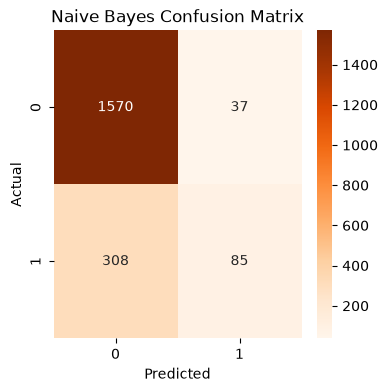

In [65]:
plt.figure(figsize=(4,4))

sns.heatmap(cm_nb, annot=True, cmap='Oranges', fmt='d')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Naive Bayes Confusion Matrix")

plt.show()

In [66]:
model_results.append({"Model":"Naive Bayes",
                       "Accuracy":nb_accuracy,
                       "Precision":nb_precision,
                       "Recall":nb_recall,
                       "F1 Score":nb_f1})

**Random Forest**

In [67]:
from sklearn.ensemble import RandomForestClassifier

In [68]:
rf_model=RandomForestClassifier()

In [69]:
rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [70]:
y_predict_rf= rf_model.predict(X_test)

In [71]:
rf_accuracy=accuracy_score(y_test, y_predict_rf)
rf_precision= precision_score(y_test, y_predict_rf)
rf_recall = recall_score(y_test, y_predict_rf)
rf_f1 = f1_score(y_test, y_predict_rf)

print("accuracy:",rf_accuracy)
print("precision:",rf_precision)
print("recall:",rf_recall)
print("F1 score:",rf_f1)


accuracy: 0.8675
precision: 0.753968253968254
recall: 0.48346055979643765
F1 score: 0.5891472868217055


In [72]:
model_results.append({"Model":"Random Forest",
                       "Accuracy":rf_accuracy,
                       "Precision":rf_precision,
                       "Recall":rf_recall,
                       "F1 Score":rf_f1})

**XG Boost**

In [73]:
%pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [74]:
from xgboost import XGBClassifier
model_xgb= XGBClassifier()

In [75]:
model_xgb.fit(X_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [76]:
y_predict_xgb= model_xgb.predict(X_test)

In [77]:
xgb_accuracy=accuracy_score(y_test, y_predict_xgb)
xgb_precision= precision_score(y_test, y_predict_xgb)
xgb_recall = recall_score(y_test, y_predict_xgb)
xgb_f1 = f1_score(y_test, y_predict_xgb)

print("accuracy:",xgb_accuracy)
print("precision:",xgb_precision)
print("recall:",xgb_recall)
print("F1 score:",xgb_f1)


accuracy: 0.8635
precision: 0.7068965517241379
recall: 0.5216284987277354
F1 score: 0.6002928257686676


In [78]:
model_results.append({"Model":"XG Boost Classifier",
                       "Accuracy":xgb_accuracy,
                       "Precision":xgb_precision,
                       "Recall":xgb_recall,
                       "F1 Score":xgb_f1})

**ANN- Artificial Neural network**

In [79]:
import tensorflow as tf
from tensorflow import keras

In [80]:
model= keras.Sequential([
    keras.layers.Input(shape=(X_train.shape[1],)),
    keras.layers.Dense(12, activation='relu'),
    keras.layers.Dense(6, activation='relu'),
    keras.layers.Dense(1, activation='sigmoid')
])

In [81]:
#Complie the model

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [82]:
history=model.fit(X_train, y_train,
                  epochs=100,
                  batch_size=32,
                  validation_split=0.2
                  )

Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.7111 - loss: 0.5618 - val_accuracy: 0.7987 - val_loss: 0.4664
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7955 - loss: 0.4572 - val_accuracy: 0.8075 - val_loss: 0.4396
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8048 - loss: 0.4357 - val_accuracy: 0.8181 - val_loss: 0.4270
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8144 - loss: 0.4206 - val_accuracy: 0.8263 - val_loss: 0.4140
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8239 - loss: 0.4054 - val_accuracy: 0.8306 - val_loss: 0.3996
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8370 - loss: 0.3903 - val_accuracy: 0.8388 - val_loss: 0.3868
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8466 - loss: 0.3773 - val_accuracy: 0.8438 - val_loss: 0.3767
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8523 - loss: 0.3669 - val_accu

In [83]:
y_pred_ann=model.predict(X_test)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [84]:
y_pred_ann=(y_pred_ann>0.5)

In [85]:
ann_accuracy=accuracy_score(y_test, y_pred_ann)
ann_precision= precision_score(y_test, y_pred_ann)
ann_recall = recall_score(y_test, y_pred_ann)
ann_f1 = f1_score(y_test, y_pred_ann)

print("accuracy:",ann_accuracy)
print("precision:",ann_precision)
print("recall:",ann_recall)
print("F1 score:",ann_f1)


accuracy: 0.8605
precision: 0.7007042253521126
recall: 0.5063613231552163
F1 score: 0.5878877400295421


In [86]:
model_results.append({"Model":"ANN Model",
                       "Accuracy":ann_accuracy,
                       "Precision":ann_precision,
                       "Recall":ann_recall,
                       "F1 Score":ann_f1})

**Conclusion**

In [87]:
result_df= pd.DataFrame(model_results)

In [88]:
result_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.8125,0.560000,0.213740,0.309392
1,KNN Classifier,0.8310,0.617021,0.368957,0.461783
2,Naive Bayes,0.8275,0.696721,0.216285,0.330097
3,Random Forest,0.8675,0.753968,0.483461,0.589147
4,XG Boost Classifier,0.8635,0.706897,0.521628,0.600293
5,ANN Model,0.8605,0.700704,0.506361,0.587888
